In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.stats.proportion import proportion_confint
from scipy.stats import chi2_contingency
from fx_analyse import(
    confidence_interval_wilson,
    khi2_independance,
    graphique_effectif_route,
)

**Question 1 - Depuis 2019, comment le nombre et la gravité des accidents de la route ont évolué ?**

In [2]:
header = ["année", 
          "n_accident", 
          "n_accident_grave",
          "pourcentage_acc_grave"
          ] #Liste des noms d'entête de chaque colonne.

gravite_accident = pd.read_csv("C:/ProgramData/MySQL/MySQL Server 8.0/Uploads/gravite_accident.csv", sep=None, engine="python", names=header, index_col=False) #Lecture du fichier csv crée par requête SQL

gravite_accident #Vérification de la bonne lecture du fichier

,année,n_accident,n_accident_grave,pourcentage_acc_grave
0,2019,56014,19932,35.58
1,2020,45119,16059,35.59
2,2021,53540,18266,34.12
3,2022,52379,18609,35.53
4,2023,51641,18551,35.92
5,2024,51057,18340,35.92


In [3]:
gravite_accident.to_csv("csv/gravite_accident.csv", index=False) #Export du fichier csv propre pour alimenter le dashboard PowerBI

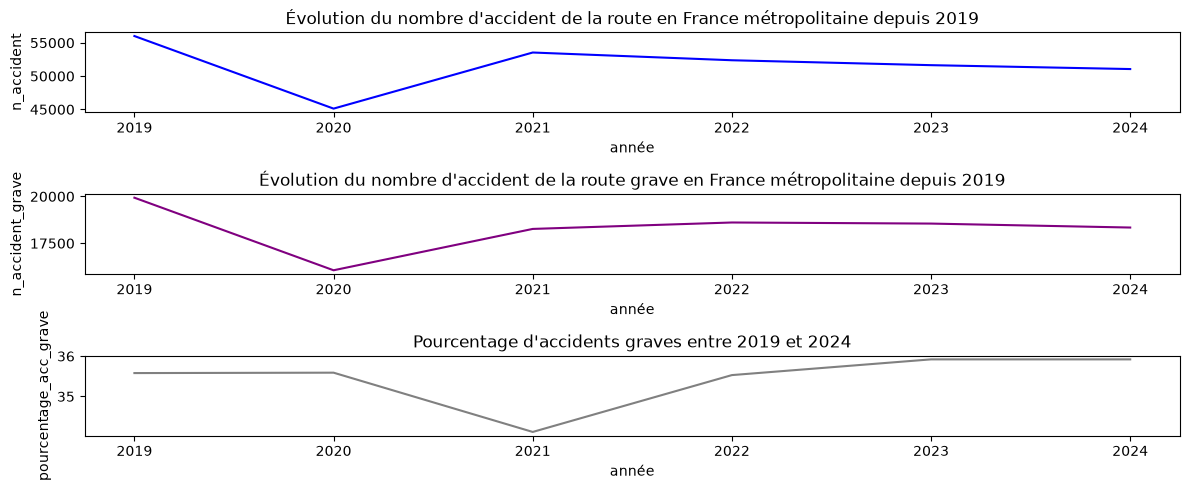

In [4]:
#Représentation graphique des données de gravité conditionnelle des accidents de la route : 

plt.figure(figsize=(12,5)) #Création de la figure
plt.subplot(3,1,1) #Création du graphique multi ligne
sns.lineplot(data=gravite_accident, y=gravite_accident["n_accident"], x=gravite_accident["année"], c="blue") #Affichage du graphique d'évolution de la variable "n_accident"
plt.title("Évolution du nombre d'accident de la route en France métropolitaine depuis 2019")
plt.tight_layout()
plt.subplot(3,1,2)
sns.lineplot(data=gravite_accident, y=gravite_accident["n_accident_grave"], x=gravite_accident["année"], c="purple") #Affichage du graphique pour la valeur "n_accident_grave"
plt.title("Évolution du nombre d'accident de la route grave en France métropolitaine depuis 2019")
plt.tight_layout()
plt.subplot(3,1,3)
sns.lineplot(data=gravite_accident, y=gravite_accident["pourcentage_acc_grave"], x=gravite_accident["année"], c="grey") #Graphique 2 - %_accident_grave
plt.title("Pourcentage d'accidents graves entre 2019 et 2024")
plt.tight_layout()

**Question 2 - Quel département concentrent le plus d'accidents graves (en valeurs absolues) ? Quels peuvent être les causes inférées de ces différences ?**

In [5]:
name = [
    "departement",
    "nombre_accident",
    "nombre_accident_grave",
    "pourcentage_accident_grave"
] #Création de la liste des entête du tableau

departement_accident = pd.read_csv("C:/ProgramData/MySQL/MySQL Server 8.0/Uploads/departement_accident.csv", sep=None, engine="python", names=name, index_col=False) #Lecture des données
departement_accident # Verification de la bonne lecture du fichier

,departement,nombre_accident,nombre_accident_grave,pourcentage_accident_grave
0,01,2627,1354,51.54
1,02,1295,857,66.18
2,03,1410,916,64.96
3,04,1212,687,56.68
4,05,1324,526,39.73
...,...,...,...,...
91,91,8098,1307,16.14
92,92,14367,1285,8.94
93,93,16595,1884,11.35
94,94,13783,1315,9.54


In [6]:
departement_accident.to_csv("csv/departement_accident.csv", index=False) #Export de la table corrigée en .csv

In [7]:
#Calcul des intervalles de confiance d'après la méthode Wilson pour la gravité des accidents : 

top_grave = confidence_interval_wilson(departement_accident, "nombre_accident_grave", "nombre_accident", "pourcentage_accident_grave")

top_grave.head(10) #Affichage des 10 départements significatifs

Le pourcentage d'accident grave sur cet échantillon est de 35.43405972558515


,departement,nombre_accident,nombre_accident_grave,pourcentage_accident_grave,ic_bas,ic_haut
22,24,1141,946,82.91,79.850998,85.587932
40,40,1046,855,81.74,78.466154,84.613648
53,53,748,610,81.55,77.625769,84.921033
70,70,642,522,81.31,77.032345,84.943969
39,39,810,614,75.80,71.726762,79.458903
15,16,881,667,75.71,71.804663,79.229833
82,82,889,667,75.03,71.112562,78.572863
46,46,604,449,74.34,69.512834,78.633776
21,23,300,222,74.00,67.007614,79.953773
88,88,1044,751,71.93,68.223032,75.369657


In [8]:
top_grave.to_csv("csv/top_10_accident_grave.csv", index=False) #Sauvegarde du résultat pour utilisation future

**Question 3 - Quel type de route concentrent le plus d’accidents graves (en valeurs absolues) ?**

In [9]:
#Setup de l'environnement de travail : 

cols_names = [
    "categorie_route",
    "ref_route",
    "nombre_accident",
    "nombre_accident_grave",
    "per_accident_grave"
] #Noms des entête de la table route_accident

route_accident = pd.read_csv("C:/ProgramData/MySQL/MySQL Server 8.0/Uploads/accident_route.csv", sep=None, engine="python", names=cols_names) #Chargement du document .csv

route_accident #Verification de la bonne lecture du fichier

,categorie_route,ref_route,nombre_accident,nombre_accident_grave,per_accident_grave
0,1,Autoroute,30111,6823,22.66
1,2,Route nationale,14904,5198,34.88
2,3,Route départementale,115478,59289,51.34
3,4,Voie communale,131060,30882,23.56
4,5,Hors réseau public,288,123,42.71
5,6,Parc de stationnement ouvert à la circulation ...,2027,755,37.25
6,7,Routes de métropole urbaine,9689,3292,33.98


In [10]:
route_accident.to_csv("csv/route_accident.csv", index=False) #Export du fichier corrigé au .csv pour lecture dans PowerBI    

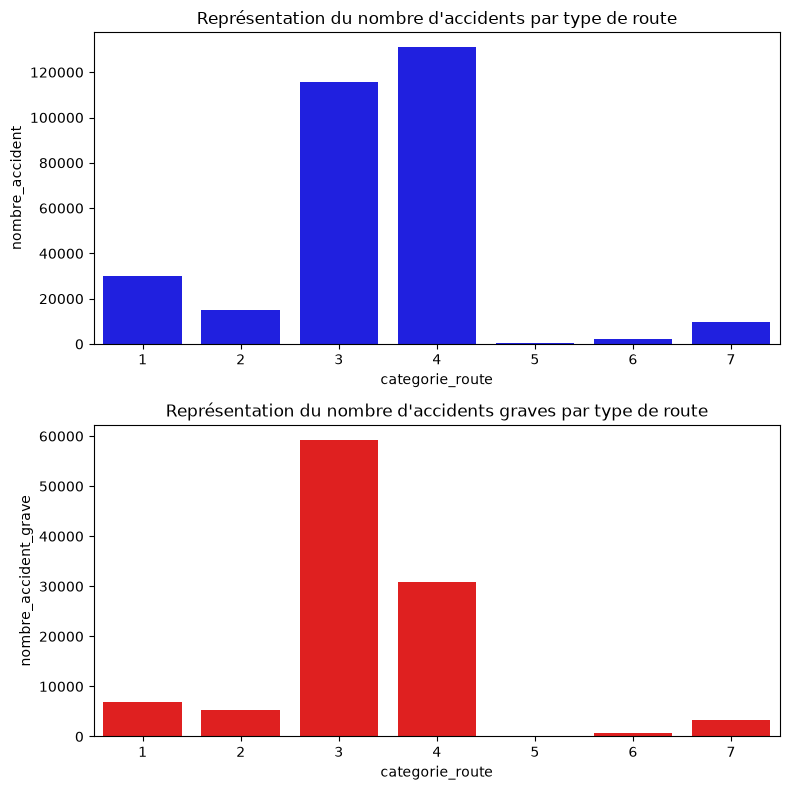

In [11]:
#Représentation graphique des effectifs :

plt.figure(figsize=(8,8)) #Création du canva
plt.subplot(2,1,1) #Visualisation en graphiques multiple pour faciliter les comparaisons
sns.barplot(route_accident, y="nombre_accident", x="categorie_route", color="blue")
plt.title("Représentation du nombre d'accidents par type de route")
plt.tight_layout()
plt.subplot(2,1,2)
sns.barplot(route_accident, y="nombre_accident_grave", x="categorie_route", color="red")
plt.title("Représentation du nombre d'accidents graves par type de route")
plt.tight_layout()

In [12]:
#Affichage du classement des routes par pourcentage d'accident grave : 

route_accident.sort_values(by="per_accident_grave", ascending=False)

,categorie_route,ref_route,nombre_accident,nombre_accident_grave,per_accident_grave
2,3,Route départementale,115478,59289,51.34
4,5,Hors réseau public,288,123,42.71
5,6,Parc de stationnement ouvert à la circulation ...,2027,755,37.25
1,2,Route nationale,14904,5198,34.88
6,7,Routes de métropole urbaine,9689,3292,33.98
3,4,Voie communale,131060,30882,23.56
0,1,Autoroute,30111,6823,22.66


In [13]:
#Calcul de l'intervalle de confiance de Wilson pour la variable nombre_accident_grave : 

route_grave = confidence_interval_wilson(route_accident, "nombre_accident_grave", "nombre_accident", "per_accident_grave") #Calcul de l'intervalle de confiance

route_grave #Affichage du résultat du calcul

Le pourcentage d'accident grave sur cet échantillon est de 35.03855947976822


,categorie_route,ref_route,nombre_accident,nombre_accident_grave,per_accident_grave,ic_bas,ic_haut
2,3,Route départementale,115478,59289,51.34,50.963319,51.721021
4,5,Hors réseau public,288,123,42.71,35.447760,50.297309


**Question 4 - Quels facteurs externes influencent la gravité d’un accident de la route ?**

In [14]:
cols_n = [
    "numero_accident",
    "gravite_max",
    "gravite_ref",
    "luminosite",
    "luminosite_ref",
    "meteo",
    "meteo_ref",
    "type_circulation",
    "type_circulation_ref",
    "type_declin",
    "type_declin_ref",
    "plan",
    "plan_ref",
    "largeur_chaussee",
    "etat_route",
    "etat_route_ref",
    "infrastructure"
] #Noms des entêtes

facteur_accident = pd.read_csv("C:/ProgramData/MySQL/MySQL Server 8.0/Uploads/facteur_externes.csv", sep=None, engine="python", names=cols_n) #Lecture du CSV SQL

facteur_accident.head(10) #Verification du bon encodage des données

,numero_accident,gravite_max,gravite_ref,luminosite,luminosite_ref,meteo,meteo_ref,type_circulation,type_circulation_ref,type_declin,type_declin_ref,plan,plan_ref,largeur_chaussee,etat_route,etat_route_ref,infrastructure
0,201900000001,2,Au moins un blessé léger,4,Nuit avec eclairage public non allume,1,Normale,3,A chaussées séparées,1,Plat,2,En courbe à gauche,\N,1,Normale,2
1,201900000002,2,Au moins un blessé léger,3,Nuit sans eclairage public,1,Normale,1,A sens unique,4,Bas de côte,2,En courbe à gauche,\N,1,Normale,0
2,201900000003,2,Au moins un blessé léger,1,Plein Jour,1,Normale,3,A chaussées séparées,1,Plat,3,En courbe à droite,\N,1,Normale,0
3,201900000004,2,Au moins un blessé léger,5,Nuit avec éclairage public allumé,1,Normale,3,A chaussées séparées,1,Plat,1,Partie rectiligne,\N,1,Normale,0
4,201900000005,2,Au moins un blessé léger,3,Nuit sans eclairage public,1,Normale,1,A sens unique,1,Plat,3,En courbe à droite,\N,1,Normale,2
5,201900000006,2,Au moins un blessé léger,1,Plein Jour,2,Pluie légère,2,Bidirectionnelle,1,Plat,1,Partie rectiligne,\N,2,Mouillée,0
6,201900000007,2,Au moins un blessé léger,2,Crépuscule ou aube,8,Temps couvert,2,Bidirectionnelle,1,Plat,1,Partie rectiligne,\N,1,Normale,0
7,201900000008,2,Au moins un blessé léger,2,Crépuscule ou aube,1,Normale,2,Bidirectionnelle,2,Pente,1,Partie rectiligne,\N,2,Mouillée,0
8,201900000009,2,Au moins un blessé léger,3,Nuit sans eclairage public,1,Normale,1,A sens unique,1,Plat,1,Partie rectiligne,\N,1,Normale,0
9,201900000010,2,Au moins un blessé léger,1,Plein Jour,1,Normale,2,Bidirectionnelle,2,Pente,1,Partie rectiligne,\N,1,Normale,0


In [15]:
facteur_accident.to_csv("csv/facteur_accident.csv", index=False) #Export du fichier nettoyé en .csv

In [16]:
facteur_accident.info()

<class 'pandas.DataFrame'>
RangeIndex: 305069 entries, 0 to 305068
Data columns (total 17 columns):
 #   Column                Non-Null Count   Dtype
---  ------                --------------   -----
 0   numero_accident       305069 non-null  int64
 1   gravite_max           305069 non-null  int64
 2   gravite_ref           305069 non-null  str  
 3   luminosite            305069 non-null  int64
 4   luminosite_ref        305069 non-null  str  
 5   meteo                 305069 non-null  int64
 6   meteo_ref             305069 non-null  str  
 7   type_circulation      305069 non-null  int64
 8   type_circulation_ref  305069 non-null  str  
 9   type_declin           305069 non-null  int64
 10  type_declin_ref       305069 non-null  str  
 11  plan                  305069 non-null  int64
 12  plan_ref              305069 non-null  str  
 13  largeur_chaussee      305069 non-null  str  
 14  etat_route            305069 non-null  int64
 15  etat_route_ref        305069 non-null  str  


In [17]:
#Nettoyage des données

for cols in cols_n : #Boucle de nettoyage des non renseignés 
    facteur_accident = facteur_accident.drop(facteur_accident[facteur_accident[cols] == -1].index)

facteur_accident.info()

<class 'pandas.DataFrame'>
Index: 284290 entries, 0 to 305068
Data columns (total 17 columns):
 #   Column                Non-Null Count   Dtype
---  ------                --------------   -----
 0   numero_accident       284290 non-null  int64
 1   gravite_max           284290 non-null  int64
 2   gravite_ref           284290 non-null  str  
 3   luminosite            284290 non-null  int64
 4   luminosite_ref        284290 non-null  str  
 5   meteo                 284290 non-null  int64
 6   meteo_ref             284290 non-null  str  
 7   type_circulation      284290 non-null  int64
 8   type_circulation_ref  284290 non-null  str  
 9   type_declin           284290 non-null  int64
 10  type_declin_ref       284290 non-null  str  
 11  plan                  284290 non-null  int64
 12  plan_ref              284290 non-null  str  
 13  largeur_chaussee      284290 non-null  str  
 14  etat_route            284290 non-null  int64
 15  etat_route_ref        284290 non-null  str  
 16  

In [18]:
facteur_accident.duplicated().sum() #Verification des duplicats possibles

np.int64(0)

In [19]:
#Calcul des liens  entre nos variables par le chi2 et V de Cramer : 

cols_evaluation = [
    "luminosite_ref",
    "meteo_ref",
    "type_circulation_ref",
    "type_declin_ref",
    "plan_ref",
    "etat_route_ref",
    "infrastructure"
] #Liste des colonnes dont l'association doit être évaluée
variable_interet = "gravite_max" #Variable d'intérêt 

for eval in cols_evaluation : 
    khi2_independance(facteur_accident, variable_interet, eval, 0.05)

L'hypothèse H0 pour la variable luminosite_ref est rejetée à 0.05, les variables sont dépendante (pval = 0.0, chi2 = 7701.982206129305, ddl = 12)
L'association par le V de Cramer entre gravite_max et luminosite_ref est faible (V = 0.0950298046195218)
L'hypothèse H0 pour la variable meteo_ref est rejetée à 0.05, les variables sont dépendante (pval = 0.0, chi2 = 2174.552297353637, ddl = 24)
L'association par le V de Cramer entre gravite_max et meteo_ref est faible (V = 0.050494434092276864)
L'hypothèse H0 pour la variable type_circulation_ref est rejetée à 0.05, les variables sont dépendante (pval = 0.0, chi2 = 13186.152410338897, ddl = 9)
L'association par le V de Cramer entre gravite_max et type_circulation_ref est faible (V = 0.12434193641215774)
L'hypothèse H0 pour la variable type_declin_ref est rejetée à 0.05, les variables sont dépendante (pval = 0.0, chi2 = 2666.1933855871584, ddl = 9)
L'association par le V de Cramer entre gravite_max et type_declin_ref est faible (V = 0.0559119

**Question 5 - Quel type de choc provoquent les accidents les plus graves en fonction du type de route ?**

In [20]:
cols_choc = [
    "type_choc",
    "n_choc",
    "n_choc_grave",
    "per_choc_grave",
    "type_route"
]

choc_accident = pd.read_csv("C:/ProgramData/MySQL/MySQL Server 8.0/Uploads/choc_accident.csv", sep=None, engine="python", names=cols_choc) #Ouverture du fichier CSV export du SQL

choc_accident.head(10) #Verification de la table

,type_choc,n_choc,n_choc_grave,per_choc_grave,type_route
0,Avant,63466,5552,8.75,Autoroute
1,Avant droit,17557,1880,10.71,Autoroute
2,Avant gauche,13861,1520,10.97,Autoroute
3,Arrière,57448,2745,4.78,Autoroute
4,Arrière droit,8096,604,7.46,Autoroute
5,Arrière gauche,12757,1075,8.43,Autoroute
6,Coté droit,8241,605,7.34,Autoroute
7,Coté gauche,10122,777,7.68,Autoroute
8,Choc multiples (tonneaux),4264,506,11.87,Autoroute
9,Avant,29882,4871,16.30,Route nationale


In [21]:
choc_accident.to_csv("csv/choc_accident.csv", index=False) #Export du fichier clean en .csv

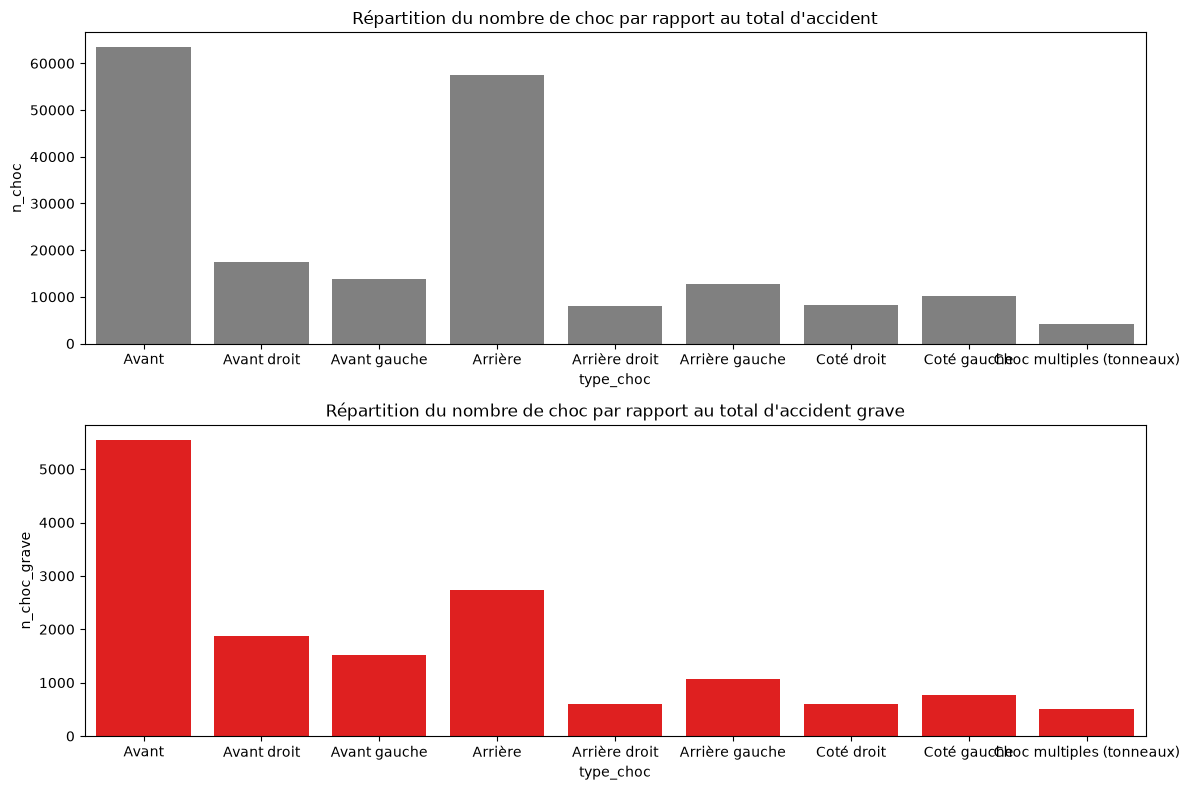

In [22]:
#Analyse des chocs sur Autoroute : 

autoroute = choc_accident.loc[choc_accident["type_route"] == "Autoroute"] #Centrage sur la valeur d'autoroute

    #Visualisation graphique des effectifs

graphique_effectif_route(autoroute)

In [23]:
#Calcul de l'interval de Wilson pour ces données : 

autoroute_grave_ic = confidence_interval_wilson(autoroute, "n_choc_grave", "n_choc", "per_choc_grave")

autoroute_grave_ic

Le pourcentage d'accident grave sur cet échantillon est de 7.795232161460993


,type_choc,n_choc,n_choc_grave,per_choc_grave,type_route,ic_bas,ic_haut
8,Choc multiples (tonneaux),4264,506,11.87,Autoroute,10.649962,13.202110
2,Avant gauche,13861,1520,10.97,Autoroute,10.300972,11.668419
1,Avant droit,17557,1880,10.71,Autoroute,10.121646,11.324000
0,Avant,63466,5552,8.75,Autoroute,8.463403,9.041203
5,Arrière gauche,12757,1075,8.43,Autoroute,7.814638,9.082076


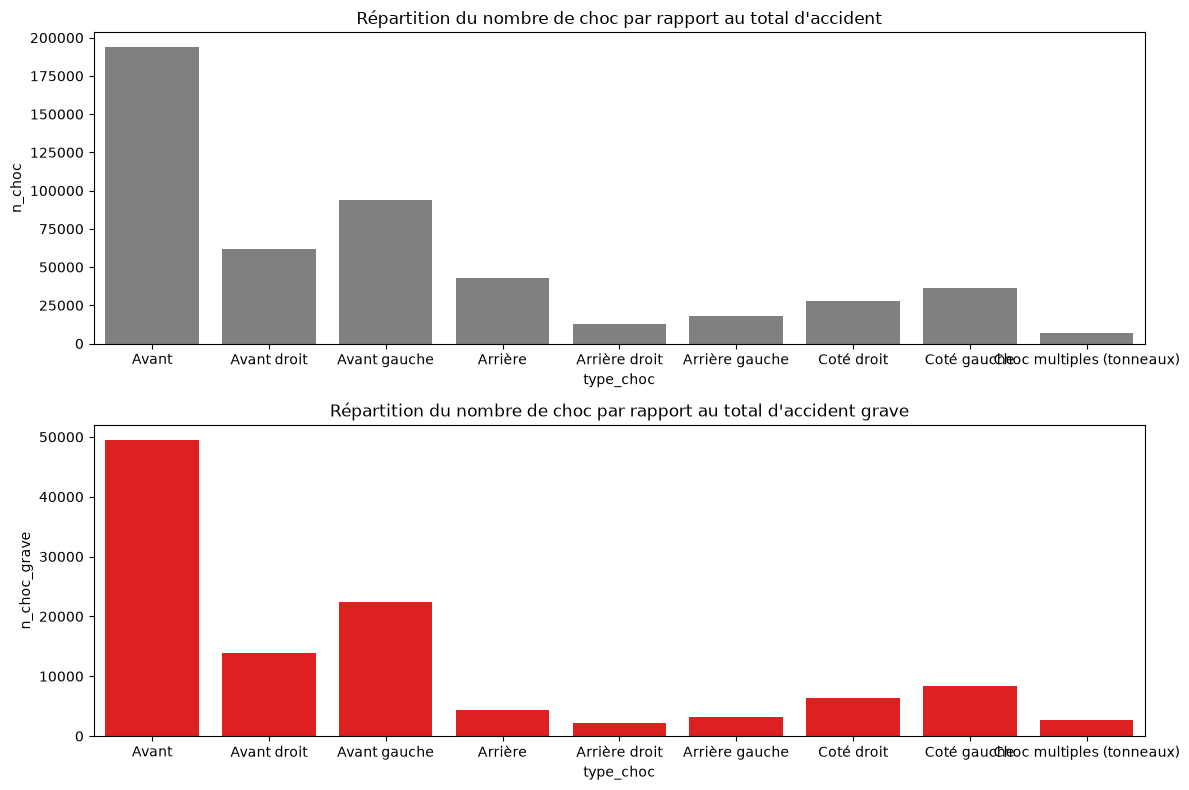

In [24]:
#Analyse des chocs sur route départementales : 

departementale = choc_accident.loc[choc_accident["type_route"] == "Route départementale"] #Centrage sur la valeur d'autoroute

    #Visualisation graphique des effectifs

graphique_effectif_route(departementale)

In [25]:
#Calcul des intervalles de confiance

departementale_ic_grave = confidence_interval_wilson(departementale, "n_choc_grave", "n_choc","per_choc_grave")

departementale_ic_grave

Le pourcentage d'accident grave sur cet échantillon est de 22.84511008083113


,type_choc,n_choc,n_choc_grave,per_choc_grave,type_route,ic_bas,ic_haut
26,Choc multiples (tonneaux),7199,2692,37.39,Route départementale,35.937428,38.873952
18,Avant,193808,49538,25.56,Route départementale,25.305967,25.816403
20,Avant gauche,94004,22447,23.88,Route départementale,23.522441,24.238788


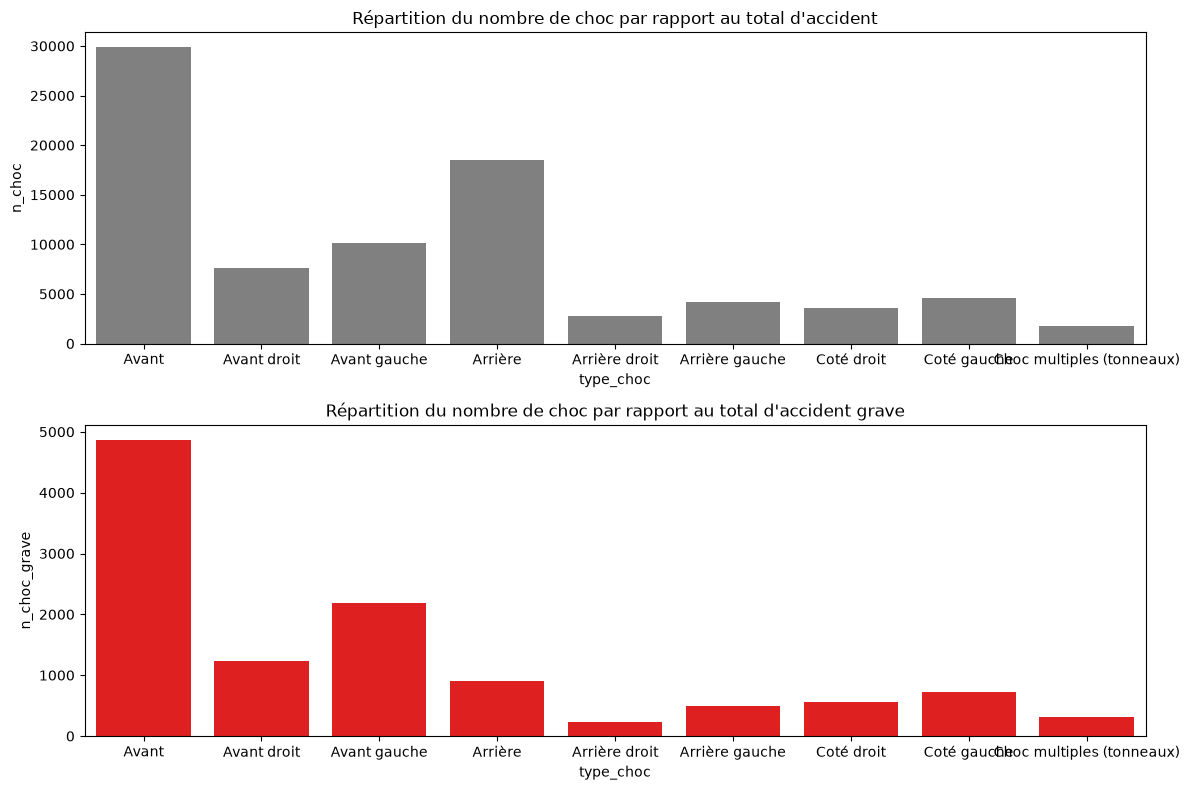

In [26]:
#Analyse des routes nationales : 

nationale = choc_accident.loc[choc_accident["type_route"] == "Route nationale"]

graphique_effectif_route(nationale)

In [27]:
nationale_ic_grave = confidence_interval_wilson(nationale, "n_choc_grave", "n_choc", "per_choc_grave")
nationale_ic_grave

Le pourcentage d'accident grave sur cet échantillon est de 13.851375749259768


,type_choc,n_choc,n_choc_grave,per_choc_grave,type_route,ic_bas,ic_haut
11,Avant gauche,10127,2188,21.61,Route nationale,20.570958,22.677441
17,Choc multiples (tonneaux),1744,315,18.06,Route nationale,15.811540,20.554404
9,Avant,29882,4871,16.30,Route nationale,15.757876,16.858652
10,Avant droit,7664,1226,16.00,Route nationale,14.947760,17.104800
16,Coté gauche,4591,720,15.68,Route nationale,14.350091,17.114672
15,Coté droit,3591,560,15.59,Route nationale,14.098657,17.217331


In [28]:
choc_avant_tonneaux = choc_accident.loc[choc_accident["type_choc"] == "Choc multiples (tonneaux)"]
choc_avant_tonneaux = choc_accident.loc[choc_accident["type_choc"] == "Avant"]


choc_avant_tonneaux.describe() #Analyse des pourcentages globaux des tonneaux peu importe le type de route


,n_choc,n_choc_grave,per_choc_grave
count,7.000000,7.000000,7.000000
mean,73195.285714,12255.857143,15.798571
std,88866.990553,18155.625496,5.378740
min,261.000000,47.000000,8.750000
25%,9917.500000,1576.000000,12.995000
50%,29882.000000,4871.000000,15.980000
75%,128637.000000,14091.500000,17.155000
max,205115.000000,49538.000000,25.560000


In [29]:
choc_noav = choc_accident.loc[choc_accident["type_choc"] != "Choc multiples (tonneaux)"]
choc_noav = choc_accident.loc[choc_accident["type_choc"] != "Avant"]


choc_noav.describe() #Verification des pourcentages globaux sans les chocs majeurs


,n_choc,n_choc_grave,per_choc_grave
count,56.000000,56.000000,56.000000
mean,14993.160714,2003.160714,14.462321
std,22504.600785,3836.601521,6.372958
min,12.000000,2.000000,4.450000
25%,729.250000,113.000000,9.997500
50%,5037.500000,604.500000,14.300000
75%,17528.500000,2105.250000,18.227500
max,94004.000000,22447.000000,37.390000


**Question 6 - Quel type d'usagers de la route sont les plus à risque de subir un accident grave ?**

In [30]:
cols_usagers = [
    "n_usager",
    "n_usager_grave",
    "n_usager_leger",
    "cat_usager",
    "cat_usager_tx"
] #Liste des entêtes de la table

usager_accident = pd.read_csv("C:/ProgramData/MySQL/MySQL Server 8.0/Uploads/usagers_accident.csv", sep=None, engine="python", names=cols_usagers) #Ouverture de la table

usager_accident["per_usager_grave"] = round((usager_accident["n_usager_grave"] / usager_accident["n_usager"]) * 100) #Rajout des pourcentages oubliés dans la requête SQL
usager_accident["per_usager_leger"] = round((usager_accident["n_usager_leger"] / usager_accident["n_usager"]) * 100)

usager_accident #Affichage de la table

,n_usager,n_usager_grave,n_usager_leger,cat_usager,cat_usager_tx,per_usager_grave,per_usager_leger
0,523097,87050,435686,1,Conducteur,17.0,83.0
1,54263,17644,36616,3,Piéton,33.0,67.0
2,125289,20582,104706,2,Passager,16.0,84.0


In [31]:
usager_accident.to_csv("csv/usager_accident.csv", index=False) #Sauvegarde en csv pour utilisation future

In [32]:
#Analyse des variables clés

usager_accident_ic = confidence_interval_wilson(usager_accident, "n_usager_grave", "n_usager", "per_usager_grave") #Calcul de l'interval de confiance

usager_accident_ic #Affichage du résultat

Le pourcentage d'accident grave sur cet échantillon est de 17.8291010162969


,n_usager,n_usager_grave,n_usager_leger,cat_usager,cat_usager_tx,per_usager_grave,per_usager_leger,ic_bas,ic_haut
1,54263,17644,36616,3,Piéton,33.0,67.0,31.999895,33.035801


In [33]:
#Verification du résultat par résidu du chi²

ct = usager_accident.set_index("cat_usager_tx")[["n_usager_grave", "n_usager_leger"]] #Création du tableau de contingence du chi²

chi2, pval, ddl, attendu = chi2_contingency(ct) #Calcul du test du chi2

res = (ct - attendu) / np.sqrt(attendu)

res["n_usager_grave"].sort_values(ascending=False)


cat_usager_tx
Piéton        80.958599
Passager     -11.821873
Conducteur   -20.295631
Name: n_usager_grave, dtype: float64

In [34]:
#Pour les catégories de véhicules : 

cols_vehic = [
    "catvehic",
    "n_vehicule",
    "n_usager_grave",
    "n_usager_leger",
    "catvehic_n"
] #Liste des entêtes de la table

vehicule_accident = pd.read_csv("C:/ProgramData/MySQL/MySQL Server 8.0/Uploads/vehicule_accident.csv", sep=None, engine="python", names=cols_vehic) #Ouverture de la table
vehicule_accident = vehicule_accident.drop("catvehic_n", axis=1) #Retrait de la variable inutile
vehicule_accident["n_usager"] = vehicule_accident["n_usager_leger"] + vehicule_accident["n_usager_grave"] #Calcul du nombre total d'usager oublié dans la requête SQL
vehicule_accident["per_usager_grave"] = round((vehicule_accident["n_usager_grave"] / (vehicule_accident["n_usager_leger"] + vehicule_accident["n_usager_grave"])) * 100) #Calcul du pourcentenge de cas graves

vehicule_accident #Affichage de la table

,catvehic,n_vehicule,n_usager_grave,n_usager_leger,n_usager,per_usager_grave
0,VL seul,852672,120742,731587,852329,14.0
1,Motocyclette > 125 cm3,88157,21968,66158,88126,25.0
2,Bicyclette,60505,9475,50987,60462,16.0
3,3RM > 125 cm3,6698,780,5915,6695,12.0
4,Autre véhicule,5476,796,4672,5468,15.0
5,Cyclomoteur <50cm3,36489,8241,28225,36466,23.0
6,Scooter > 125 cm3,11530,1765,9755,11520,15.0
7,Scooter > 50 cm3 et <= 125 cm3,23344,2816,20515,23331,12.0
8,"PL seul > 7,5T",10494,1914,8578,10492,18.0
9,"VU seul 1,5T <= PTAC <= 3,5T avec ou sans remo...",100165,12596,87522,100118,13.0


In [35]:
vehicule_accident.to_csv("csv/vehicule_accident.csv", index=False) #Sauvegarde pour utilisation ultérieure

In [36]:
#Calcul de l'intervalle de confiance : 

vehicule_accident_ic = confidence_interval_wilson(vehicule_accident, "n_usager_grave", "n_usager", "per_usager_grave")

vehicule_accident_ic

Le pourcentage d'accident grave sur cet échantillon est de 15.212644712374782


,catvehic,n_vehicule,n_usager_grave,n_usager_leger,n_usager,per_usager_grave,ic_bas,ic_haut
14,Quad lourd > 50 cm3 (Quadricycle à moteur non ...,1648,777,870,1647,47.0,44.025906,50.350120
27,Quad léger <= 50 cm3 (Quadricycle à moteur non...,227,83,142,225,37.0,29.089689,45.439192
23,Tracteur agricole,3254,1186,2068,3254,36.0,34.303820,38.646233
26,Train,496,173,323,496,35.0,29.599375,40.557890
1,Motocyclette > 125 cm3,88157,21968,66158,88126,25.0,24.554481,25.305182
5,Cyclomoteur <50cm3,36489,8241,28225,36466,23.0,22.040001,23.168235
16,"PL > 3,5T + remorque",14990,3218,11769,14987,21.0,20.620677,22.348456
17,Tracteur routier + semi-remorque,10598,2243,8355,10598,21.0,20.160530,22.204294
15,Motocyclette > 50 cm3 et <= 125 cm3,18675,3795,14873,18668,20.0,19.580799,21.098095
8,"PL seul > 7,5T",10494,1914,8578,10492,18.0,17.291474,19.233607


In [37]:
#Verification du résultat par résidu du chi²

ct = vehicule_accident.set_index("catvehic")[["n_usager_grave", "n_usager_leger"]] #Création du tableau de contingence du chi²

chi2, pval, ddl, attendu = chi2_contingency(ct) #Calcul du test du chi2

res = (ct - attendu) / np.sqrt(attendu) #Calcul des résidus

res = res.loc[res["n_usager_grave"] > 3] #Affichage des résultat significatif à alpha = 0.001

res["n_usager_grave"].sort_values(ascending=False)

catvehic
Motocyclette > 125 cm3                                      73.944496
Cyclomoteur <50cm3                                          36.164273
Quad lourd > 50 cm3 (Quadricycle à moteur non carrossé)     33.258764
Tracteur agricole                                           31.056655
PL > 3,5T + remorque                                        19.646292
Motocyclette > 50 cm3 et <= 125 cm3                         17.922524
Tracteur routier + semi-remorque                            15.709144
Train                                                       11.229569
Quad léger <= 50 cm3 (Quadricycle à moteur non carrossé)     8.336292
PL seul > 7,5T                                               7.956910
Name: n_usager_grave, dtype: float64

**Question 7 - Quel est le profil démographique le plus représenté dans les accidents graves ?**

In [38]:
cols_genre_ct = [
    "sexe",
    "n_usager",
    "n_usager_grave",
    "per_usagers_grave"
] #Liste des entêtes de la table

genre_accident_ct = pd.read_csv("C:/ProgramData/MySQL/MySQL Server 8.0/Uploads/genre_count.csv", sep=None, engine="python", names=cols_genre_ct) #Ouverture de la table

genre_accident_ct #Affichage de la table

,sexe,n_usager,n_usager_grave,per_usagers_grave
0,Masculin,472994,89782,18.98
1,Féminin,219601,35494,16.16


In [39]:
genre_accident_ct.to_csv("csv/genre_accident_ct.csv", index=False) #Sauvegarde pour utilisation future

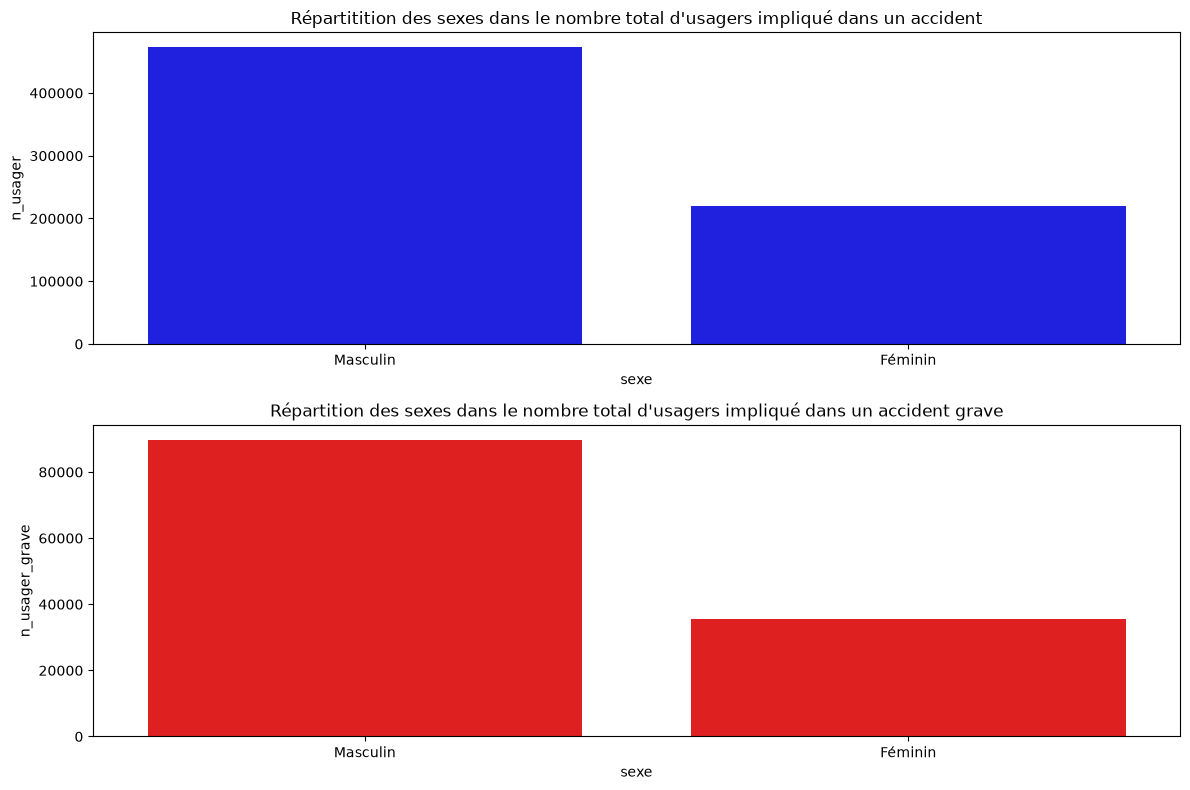

In [40]:
#Visualisation graphique des effectifs des deux groupes : 

plt.figure(figsize=(12,8))
plt.subplot(2,1,1)
plt.title("Répartitition des sexes dans le nombre total d'usagers impliqué dans un accident")
sns.barplot(genre_accident_ct, y="n_usager", x="sexe", color="blue")
plt.tight_layout()
plt.subplot(2,1,2)
plt.title("Répartition des sexes dans le nombre total d'usagers impliqué dans un accident grave")
sns.barplot(genre_accident_ct, y="n_usager_grave", x="sexe", color="red")
plt.tight_layout()

In [41]:
#Calcul de l'Intervalle de confiance de Wilson : 

genre_accident_ct_wilson = confidence_interval_wilson(genre_accident_ct, "n_usager_grave", "n_usager", "per_usagers_grave")

genre_accident_ct_wilson

Le pourcentage d'accident grave sur cet échantillon est de 18.087915737191288


,sexe,n_usager,n_usager_grave,per_usagers_grave,ic_bas,ic_haut
0,Masculin,472994,89782,18.98,18.835197,19.128946


In [42]:
#Confirmation via les résidu du Chi2 : 

    #Calcul des accidents légers non présent dans les données: 

genre_accident_ct["n_usager_leger"] = genre_accident_ct["n_usager"] - genre_accident_ct["n_usager_grave"]

    #Calcul des résidus du Chi² :

ct = genre_accident_ct.set_index("sexe")[["n_usager_leger", "n_usager_grave"]] #Création du tableau de contingence du chi²

chi2, pval, ddl, attendu = chi2_contingency(ct) #Calcul du test du chi2

res = (ct - attendu) / np.sqrt(attendu) #Calcul du résidu

res = res.loc[res["n_usager_grave"] > 3] #Affichage des résultats significatifs à alpha = 0.001

res["n_usager_grave"].sort_values(ascending=False)

sexe
Masculin    14.452242
Name: n_usager_grave, dtype: float64

In [43]:
#Partie 2 de la question sur les ages : 

cols_genre = [
    "annee_accident",
    "sexe",
    "sexe_txt",
    "gravite",
    "an_nais",
    "age_usager"
] #Entêtes de la table

genre_accident = pd.read_csv("C:/ProgramData/MySQL/MySQL Server 8.0/Uploads/genre_accident_ng.csv", sep=None, engine="python", names=cols_genre) #Ouverture du .csv
genre_accident = genre_accident.drop("sexe", axis=1)

genre_accident #Verification de la bonne lecture de la table

,annee_accident,sexe_txt,gravite,an_nais,age_usager
0,2019,Masculin,2,1962,57
1,2019,Masculin,3,1971,48
2,2019,Masculin,2,1971,48
3,2019,Masculin,3,1981,38
4,2019,Masculin,3,2010,9
...,...,...,...,...,...
125271,2024,Masculin,3,2006,18
125272,2024,Masculin,3,2006,18
125273,2024,Masculin,3,1947,77
125274,2024,Masculin,3,1997,27


In [44]:
genre_accident.to_csv("csv/genre_accident", index=False) #Sauvegarde pour utilisation future

In [45]:
genre_accident.info() #Verification des bonnes données pour les ages et dates

<class 'pandas.DataFrame'>
RangeIndex: 125276 entries, 0 to 125275
Data columns (total 5 columns):
 #   Column          Non-Null Count   Dtype
---  ------          --------------   -----
 0   annee_accident  125276 non-null  int64
 1   sexe_txt        125276 non-null  str  
 2   gravite         125276 non-null  int64
 3   an_nais         125276 non-null  str  
 4   age_usager      125276 non-null  str  
dtypes: int64(2), str(3)
memory usage: 4.8 MB


In [46]:
genre_accident.age_usager = pd.to_numeric(genre_accident.age_usager, errors="coerce") #Passage des ages au format numerique

In [47]:
genre_accident.info() #Verification

<class 'pandas.DataFrame'>
RangeIndex: 125276 entries, 0 to 125275
Data columns (total 5 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   annee_accident  125276 non-null  int64  
 1   sexe_txt        125276 non-null  str    
 2   gravite         125276 non-null  int64  
 3   an_nais         125276 non-null  str    
 4   age_usager      125275 non-null  float64
dtypes: float64(1), int64(2), str(2)
memory usage: 4.8 MB


In [48]:
#Nettoyage des valeurs absurdes : 

genre_accident.describe()

,annee_accident,gravite,age_usager
count,125276.000000,125276.000000,125275.000000
mean,2021.502299,2.853539,41.790054
std,1.725826,0.353569,21.525150
min,2019.000000,2.000000,0.000000
25%,2020.000000,3.000000,23.000000
50%,2022.000000,3.000000,38.000000
75%,2023.000000,3.000000,58.000000
max,2024.000000,3.000000,120.000000


On a un max à 120 ans ce qui paraît légèrement élevé, résultant probablement d'une erreur d'entrée dans la base on va donc retirer ces données

In [49]:
#Verification de la cause de ce max : 

genre_accident.loc[genre_accident["age_usager"] == 120]

,annee_accident,sexe_txt,gravite,an_nais,age_usager
53612,2020,Masculin,3,1900,120.0


On apperçois qu'il s'agit d'une date entrée arbitrairement : 1900 on va donc supprimer cela

In [50]:
genre_accident = genre_accident.drop(genre_accident[genre_accident["an_nais"] == "1900"].index)

In [51]:
genre_accident.describe()

,annee_accident,gravite,age_usager
count,125267.000000,125267.000000,125266.000000
mean,2021.502471,2.853529,41.784499
std,1.725767,0.353579,21.515943
min,2019.000000,2.000000,0.000000
25%,2020.000000,3.000000,23.000000
50%,2022.000000,3.000000,38.000000
75%,2023.000000,3.000000,58.000000
max,2024.000000,3.000000,118.000000


In [52]:
genre_accident.loc[genre_accident["age_usager"] == 118]

,annee_accident,sexe_txt,gravite,an_nais,age_usager
43416,2019,Masculin,3,1901,118.0


In [53]:
genre_accident = genre_accident.drop(genre_accident[genre_accident["an_nais"] == "1901"].index)

In [54]:
genre_accident.describe()

,annee_accident,gravite,age_usager
count,125266.000000,125266.000000,125265.000000
mean,2021.502491,2.853528,41.783890
std,1.725759,0.353580,21.514951
min,2019.000000,2.000000,0.000000
25%,2020.000000,3.000000,23.000000
50%,2022.000000,3.000000,38.000000
75%,2023.000000,3.000000,58.000000
max,2024.000000,3.000000,109.000000


109 paraît plus plausible sachant qu'on peux avoir des individu de ces ages là dans des accidents

<Axes: xlabel='age_usager', ylabel='Count'>

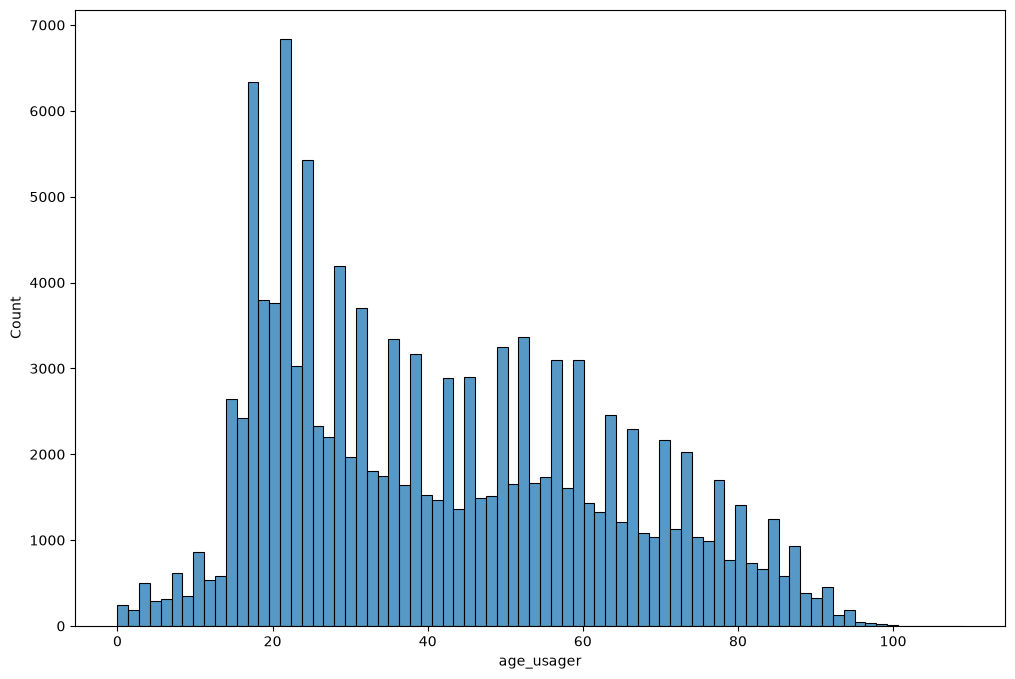

In [55]:
#Analyse de la distribution des age : 

plt.figure(figsize=(12,8))
sns.histplot(data=genre_accident, x="age_usager")

In [68]:
#Confirmation de la distribution : 

skewness = genre_accident["age_usager"].skew()
kurto = genre_accident["age_usager"].kurtosis()

print(f"La distribution de l'age des usagers suit un skewness de {skewness} et un kurtosis de {kurto}")

La distribution de l'age des usagers suit un skewness de 0.4354632093554737 et un kurtosis de -0.847846013012092


<Axes: ylabel='age_usager'>

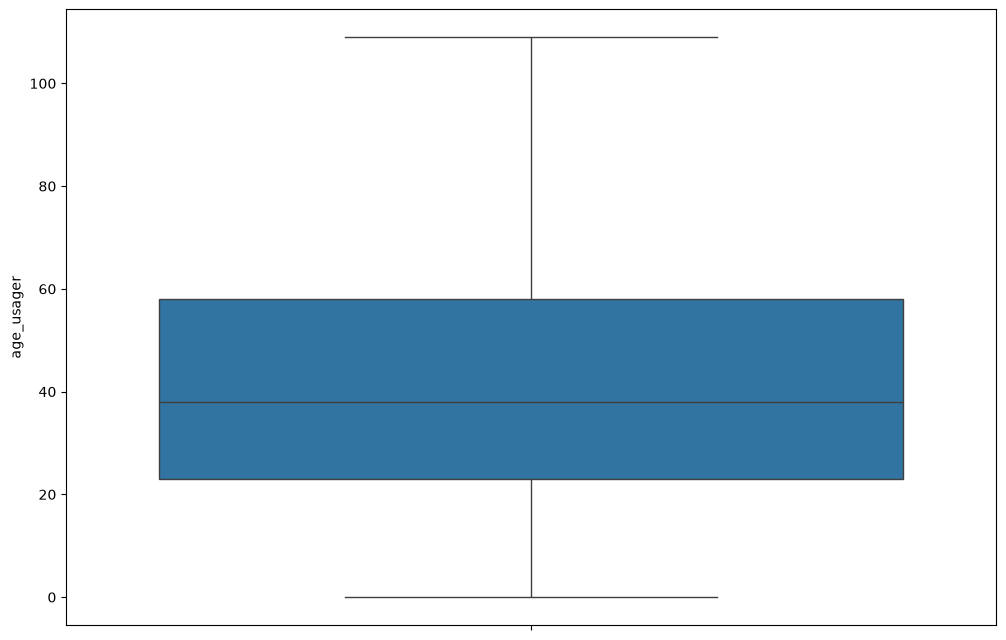

In [67]:
#Verification des valeurs abbérantes : 

plt.figure(figsize=(12,8))
sns.boxplot(data=genre_accident["age_usager"])

In [58]:
#Calcul de l'age médian par genre :

genre_accident.groupby("sexe_txt").age_usager.mean() #Calcul de la médiane de l'age dans un accident grave


sexe_txt
Féminin     46.419012
Masculin    39.951310
Name: age_usager, dtype: float64

In [59]:
genre_accident.age_usager.mean()

np.float64(41.783890152875905)

In [60]:
#Rajout de la table contnenant tous les types d'accident : 

cols_genre = [
    "annee_accident",
    "sexe",
    "sexe_txt",
    "gravite",
    "an_nais",
    "age_usager"
] #Entêtes de la table

genre_accident_total = pd.read_csv("C:/ProgramData/MySQL/MySQL Server 8.0/Uploads/genre_total_accident_ng.csv", sep=None, engine="python", names=cols_genre) #Ouverture du .csv
genre_accident_total = genre_accident_total.drop("sexe", axis=1)

genre_accident_total #Verification de la bonne lecture de la table

,annee_accident,sexe_txt,gravite,an_nais,age_usager
0,2019,Masculin,4,1935,84
1,2019,Masculin,4,2016,3
2,2019,Masculin,1,1973,46
3,2019,Masculin,4,1989,30
4,2019,Masculin,1,1989,30
...,...,...,...,...,...
692587,2024,Masculin,3,1995,29
692588,2024,Masculin,4,2009,15
692589,2024,Masculin,1,1973,51
692590,2024,Masculin,4,2002,22


In [61]:
#Encodage des usagers grave et leger : 

def usager_type(df : pd.DataFrame) -> pd.DataFrame : 
    if df["gravite"] == 1 :
        return "Accident léger"
    elif df["gravite"] == 4 : 
        return "Accident léger"
    else :
        return "Accident grave"

genre_accident_total["categorie"] = genre_accident_total.apply(usager_type, axis=1)

genre_accident_total.age_usager = pd.to_numeric(genre_accident_total.age_usager, errors="coerce")

genre_accident_total

,annee_accident,sexe_txt,gravite,an_nais,age_usager,categorie
0,2019,Masculin,4,1935,84.0,Accident léger
1,2019,Masculin,4,2016,3.0,Accident léger
2,2019,Masculin,1,1973,46.0,Accident léger
3,2019,Masculin,4,1989,30.0,Accident léger
4,2019,Masculin,1,1989,30.0,Accident léger
...,...,...,...,...,...,...
692587,2024,Masculin,3,1995,29.0,Accident grave
692588,2024,Masculin,4,2009,15.0,Accident léger
692589,2024,Masculin,1,1973,51.0,Accident léger
692590,2024,Masculin,4,2002,22.0,Accident léger


In [62]:
#Suppression des valeurs abérante identifiée précédemment : 

genre_accident_total = genre_accident_total.drop(genre_accident_total[genre_accident_total["an_nais"] == "1900"].index)
genre_accident_total = genre_accident_total.drop(genre_accident_total[genre_accident_total["an_nais"] == "1901"].index)

<Axes: ylabel='age_usager'>

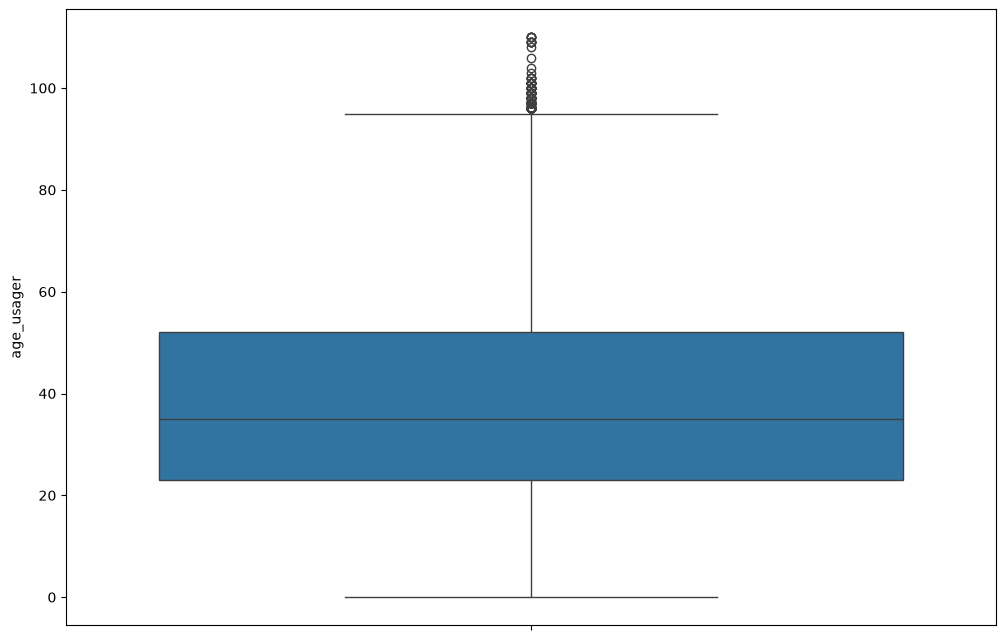

In [63]:
#Verification des valeurs abbérantes : 

plt.figure(figsize=(12,8))
sns.boxplot(data=genre_accident_total["age_usager"])

In [64]:
genre_accident_total.groupby(["sexe_txt", "categorie"]).age_usager.median() #Calcul de la médiane de l'age par rapport au type d'accident

sexe_txt  categorie     
Féminin   Accident grave    46.0
          Accident léger    35.0
Masculin  Accident grave    36.0
          Accident léger    35.0
Name: age_usager, dtype: float64

In [65]:
genre_accident_total.groupby(["sexe_txt", "categorie"]).age_usager.agg(["min", "max"]) #Calcul de la médiane de l'age par rapport au type d'accident

min    max
sexe_txt categorie                 
Féminin  Accident grave  0.0  109.0
         Accident léger  0.0  110.0
Masculin Accident grave  0.0  109.0
         Accident léger  0.0  110.0

In [66]:
genre_accident_total.loc[genre_accident_total["age_usager"] == 0]

,annee_accident,sexe_txt,gravite,an_nais,age_usager,categorie
1258,2019,Masculin,2,2019,0.0,Accident grave
2616,2019,Masculin,4,2019,0.0,Accident léger
2727,2019,Masculin,1,2019,0.0,Accident léger
3073,2019,Masculin,4,2019,0.0,Accident léger
4230,2019,Masculin,1,2019,0.0,Accident léger
...,...,...,...,...,...,...
688989,2024,Masculin,1,2024,0.0,Accident léger
689048,2024,Masculin,1,2024,0.0,Accident léger
690083,2024,Masculin,1,2024,0.0,Accident léger
690946,2024,Masculin,4,2024,0.0,Accident léger
